# Chi-Square Distribution

This notebook accompanies [Chi-Square Distribution](../../notes/sampling_and_sampling_distributions/chi_square_distribution.md). We build the chi-square from squared standard normals, check the density, CDF and moments against `scipy.stats`, and run the goodness-of-fit and variance procedures from the note.

## Sum of squared standard normals

If $Z_1,\dots,Z_k$ are independent $N(0,1)$ then $\sum Z_i^2\sim\chi^2(k)$.

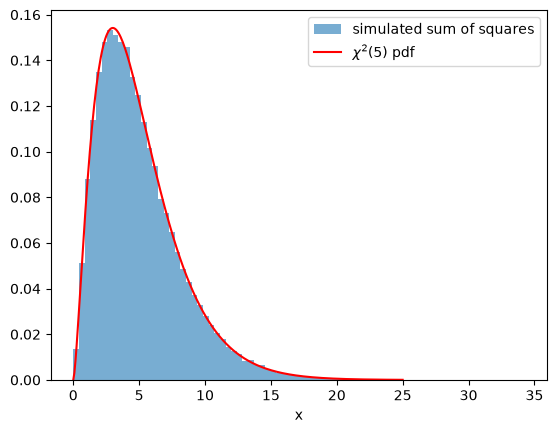

mean: 5.008 (k = 5 )  variance: 10.094 (2k = 10 )


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)

k = 5
q = (rng.standard_normal(size=(100_000, k)) ** 2).sum(axis=1)
xs = np.linspace(0, 25, 300)
plt.hist(q, bins=80, density=True, alpha=0.6, label="simulated sum of squares")
plt.plot(xs, stats.chi2.pdf(xs, k), "r", label=r"$\chi^2(5)$ pdf")
plt.legend(); plt.xlabel("x"); plt.show()
print("mean:", round(q.mean(), 3), "(k =", k, ")  variance:", round(q.var(ddof=1), 3), "(2k =", 2 * k, ")")

## Formulas versus `scipy.stats`

The pdf $\frac{1}{2^{k/2}\Gamma(k/2)}x^{k/2-1}e^{-x/2}$ and the CDF $\gamma(k/2,x/2)/\Gamma(k/2)$ (the regularized lower incomplete gamma function, `scipy.special.gammainc`) agree with `scipy.stats.chi2`.

In [2]:
from scipy.special import gamma, gammainc

x = np.linspace(0.1, 20, 200)
for k in (2, 5, 10):
    pdf_formula = x ** (k / 2 - 1) * np.exp(-x / 2) / (2 ** (k / 2) * gamma(k / 2))
    cdf_formula = gammainc(k / 2, x / 2)
    print(k, np.allclose(pdf_formula, stats.chi2.pdf(x, k)), np.allclose(cdf_formula, stats.chi2.cdf(x, k)),
          " mean/var:", stats.chi2.mean(k), stats.chi2.var(k))

2 True True  mean/var: 2.0 4.0
5 True True  mean/var: 5.0 10.0
10 True True  mean/var: 10.0 20.0


## Goodness of fit for a die

Counts from 120 rolls: $(25,17,15,23,24,16)$ against $E=20$. We verify the statistic by hand and with `scipy.stats.chisquare`. The note's 60-roll example, $(8,9,13,7,12,11)$, gives $\chi^2=2.8$.

In [3]:
obs = np.array([25, 17, 15, 23, 24, 16])
exp = np.full(6, obs.sum() / 6)
chi2_stat = np.sum((obs - exp) ** 2 / exp)
print("by hand:", chi2_stat, " p =", round(stats.chi2.sf(chi2_stat, 5), 4))
print("scipy  :", stats.chisquare(obs))

obs60 = np.array([8, 9, 13, 7, 12, 11])
res = stats.chisquare(obs60)
print("60-roll example:", res.statistic, round(res.pvalue, 4), "critical value (5%):", round(stats.chi2.ppf(0.95, 5), 3))

by hand: 5.0  p = 0.4159
scipy  : Power_divergenceResult(statistic=np.float64(5.0), pvalue=np.float64(0.4158801869955079))
60-roll example: 2.8 0.7308 critical value (5%): 11.07


## Test of independence

For the table $\begin{pmatrix}30&20\\20&30\end{pmatrix}$ each expected count is $25$ and $\chi^2=4$ on $1$ df.

In [4]:
table = np.array([[30, 20], [20, 30]])
chi2_val, p, dof, expected = stats.chi2_contingency(table, correction=False)
print("chi2 =", chi2_val, " dof =", dof, " p =", round(p, 4))
print("expected counts:\n", expected)

chi2 = 4.0  dof = 1  p = 0.0455
expected counts:
 [[25. 25.]
 [25. 25.]]


## Inference for a variance

For normal data, $(n-1)S^2/\sigma^2\sim\chi^2(n-1)$. With $n=16$, $s^2=25$ the 95% interval for $\sigma^2$ is $\left(\frac{(n-1)s^2}{\chi^2_{0.975}},\frac{(n-1)s^2}{\chi^2_{0.025}}\right)$. We also verify coverage by simulation.

In [5]:
n, s2 = 16, 25.0
lo = (n - 1) * s2 / stats.chi2.ppf(0.975, n - 1)
hi = (n - 1) * s2 / stats.chi2.ppf(0.025, n - 1)
print("95% CI for sigma^2:", round(lo, 2), round(hi, 2))

true_var = 25.0
s2_sim = rng.normal(0, 5, size=(20_000, n)).var(axis=1, ddof=1)
covered = ((n - 1) * s2_sim / stats.chi2.ppf(0.975, n - 1) <= true_var) & \
          (true_var <= (n - 1) * s2_sim / stats.chi2.ppf(0.025, n - 1))
print("Simulated coverage:", round(covered.mean(), 4))

# test H0: sigma^2 = 16, n = 21, s^2 = 25
stat = 20 * 25 / 16
print("test statistic:", stat, " p =", round(stats.chi2.sf(stat, 20), 4))

95% CI for sigma^2: 13.64 59.88
Simulated coverage: 0.9484
test statistic: 31.25  p = 0.052
